# v8.0 candidate --- idle-cash yield (cash-management accounting)

**Question.** The delta-neutral funding-carry backtest books idle cash at **0% yield**. Crediting
idle cash at the short risk-free rate, how much does it change the three shipped books
(v6.1 Binance-only, v7.0 multi-venue breadth, v7.1 multi-venue full book) --- and is a v8.0 accounting
change justified?

**Where the idle cash is.** On *deployed* days the book is fully invested (weights renormalize to 1,
idle ~0). So essentially **all** idle cash comes from the **v4 drawdown overlay sitting 100% in
cash** --- ~21% of all days, and (as we confirm below) that idle is **binary and almost entirely in
2022 (~92% of the year) and early 2023**, exactly the window when 3-month T-bill rates ramped
**0 -> 5%**. A market-neutral book that sits flat at 0% through a 5% rate regime is leaving the
risk-free rate on the table.

**Method.** For each book: `idle_t = (1 - sum W_t).clip(0)`; `rf_daily` = monthly TB3MS / 365,
forward-filled to days; `cash_pnl_t = idle_t * rf_daily_t`; `net_with_cash = net + cash_pnl` at 1x and
2x cost. Report **before vs after**: annual return, maxDD, Calmar, **raw Sharpe (vs 0)** AND the
honest **excess Sharpe (of net_with_cash over rf)**. Crediting rf and then quoting raw Sharpe would
inflate it mechanically --- the fair presentation is total return up + Sharpe measured in excess of
the same rf. We also report the excess Sharpe of the *current* (uncredited) books: the honest baseline
in a 5% world. All three books are read from `results/funding_carry/`; every stored metric is
re-derived from the parquet and asserted against `metrics.json` first.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'svg'
import json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
_p = Path.cwd().resolve()
ROOT = next((q for q in [_p, *_p.parents] if (q/'pyproject.toml').exists()), _p)
RES = ROOT / 'results' / 'funding_carry'
plt.rcParams.update({'figure.figsize':(14,3.8),'axes.grid':True,'grid.alpha':0.25,
                     'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
NAVY,TEAL,AMBER,RED,GREY='#1f3a5f','#2a9d8f','#e0a32e','#c1121f','0.6'
YEAR = 365.0

# Stored books. v7.0 uses the 091117Z run (matches the cited headline + shares the 2021-01 start);
# the later 091322Z v7.0 dir is a joint-period (2021-08 start) variant -- see module docstring.
RUNS = {'v6.1': RES/'v6.1'/'20260703T091044Z',
        'v7.0': RES/'v7.0'/'20260703T091117Z',
        'v7.1': RES/'v7.1'/'20260703T091157Z'}

# --- TB3MS 3-month T-bill, monthly, percent. BEST-KNOWLEDGE APPROXIMATION (FRED live fetch blocked
#     2026-07-03; https://fred.stlouisfed.org/graph/fredgraph.csv?id=TB3MS). 2021-23 track the real
#     series; 2024-26 anchored to public reporting. Result is insensitive to 2024-26 (idle=0 there).
TB3MS = {
 '2021':[0.08,0.04,0.03,0.02,0.02,0.04,0.05,0.05,0.04,0.05,0.05,0.06],
 '2022':[0.15,0.33,0.44,0.76,0.85,1.16,2.30,2.63,3.13,3.72,4.15,4.25],
 '2023':[4.54,4.65,4.72,4.98,5.14,5.24,5.28,5.30,5.32,5.33,5.27,5.24],
 '2024':[5.22,5.24,5.24,5.24,5.25,5.24,5.20,5.13,4.88,4.63,4.55,4.34],
 '2025':[4.30,4.29,4.29,4.30,4.31,4.28,4.20,4.05,3.90,3.78,3.72,3.68],
 '2026':[3.75,3.78,3.80,3.80,3.78,None,None,None,None,None,None,None]}
_rec = {pd.Timestamp(f'{y}-{mo:02d}-01'): v/100.0
        for y, vals in TB3MS.items() for mo, v in enumerate(vals, 1) if v is not None}
RF_M = pd.Series(_rec).sort_index()

def rf_daily(idx):
    '''Monthly TB3MS forward-filled to a daily index, expressed as a daily rate (annual%/100/365).'''
    key = idx.to_period('M').to_timestamp()
    return pd.Series(RF_M.reindex(key).ffill().values, index=idx) / YEAR

def load(name):
    '''Load one book: net (1x), net2 (2x rebuilt = 2*net - gross), gross, idle fraction, rf.'''
    d = RUNS[name]
    r = pd.read_parquet(d/'returns.parquet'); w = pd.read_parquet(d/'weights.parquet')
    net, gross = r['net'], r['gross']
    net2 = 2*r['net'] - r['gross']                        # net_2x = gross - 2*(gross-net) = 2*net - gross
    idle = (1 - w.sum(axis=1)).clip(lower=0).reindex(r.index).fillna(0.0)
    return dict(name=name, r=r, w=w, net=net, net2=net2, gross=gross,
                idle=idle, rf=rf_daily(r.index), mj=json.loads((d/'metrics.json').read_text()))

def perf(net, rf=None):
    '''engine-parity metrics: ann=mean*365, vol=std*sqrt(365), Sharpe=ann/vol, maxDD via (1+net).cumprod.
    If rf given, also the excess-of-rf Sharpe (mean/std of net-rf, annualized).'''
    net = net.dropna()
    ann = net.mean()*YEAR; vol = net.std()*np.sqrt(YEAR)
    cum = (1+net).cumprod(); dd = float((cum/cum.cummax()-1).min())
    out = dict(ann=ann, sharpe=ann/vol, maxdd=dd, calmar=ann/abs(dd))
    if rf is not None:
        ex = (net - rf.reindex(net.index)); out['exc_sharpe'] = (ex.mean()*YEAR)/(ex.std()*np.sqrt(YEAR))
    return out

BOOKS = {n: load(n) for n in RUNS}

# PARITY: the parquet net series must reproduce metrics.json 1x AND 2x (proves we read the right series).
for n, b in BOOKS.items():
    for mult, s in [('1.0x', b['net']), ('2.0x', b['net2'])]:
        p = perf(s); ref = b['mj']['results'][mult]
        assert abs(round(p['ann'],4)-ref['ann_return'])<1e-4, (n, mult, 'ann')
        assert abs(round(p['sharpe'],3)-ref['sharpe'])<2e-3, (n, mult, 'sharpe')
        assert abs(round(p['maxdd'],4)-ref['max_drawdown'])<1e-4, (n, mult, 'maxdd')
print('parity OK -- parquet reproduces metrics.json (1x & 2x) for all three books')
print('full-sample rf mean:', round(BOOKS['v6.1']['rf'].mean()*YEAR*100,2), '%/yr')
for n, b in BOOKS.items():
    ni = int((b['idle']>0.5).sum())
    print(f"{n}: idle>0.5 on {ni} days ({ni/len(b['r'])*100:.1f}%); "
          f"avg rf on idle days {b['rf'][b['idle']>0.5].mean()*YEAR*100:.2f}%/yr; "
          f"cash uplift {(b['idle']*b['rf']).mean()*YEAR*100:.3f}%/yr")

parity OK -- parquet reproduces metrics.json (1x & 2x) for all three books
full-sample rf mean: 3.34 %/yr
v6.1: idle>0.5 on 445 days (22.9%); avg rf on idle days 2.77%/yr; cash uplift 0.633%/yr
v7.0: idle>0.5 on 432 days (22.2%); avg rf on idle days 2.70%/yr; cash uplift 0.600%/yr
v7.1: idle>0.5 on 358 days (18.4%); avg rf on idle days 2.48%/yr; cash uplift 0.457%/yr


## 1. The rate environment vs where the idle cash sits

The idle fraction is **binary** (the v4 overlay is fully on or fully out; when on, weights renormalize
to 1 so idle ~0). It is concentrated in **2022 and early 2023** and is ~0 everywhere else --- the
overlay never sits out after mid-2023. That window coincides exactly with the 3-month T-bill climbing
from ~0% to ~5%. So the entire cash-yield opportunity is earned in 2022-early-2023; the (approximate)
2024-2026 rates are irrelevant because there is no idle cash then.

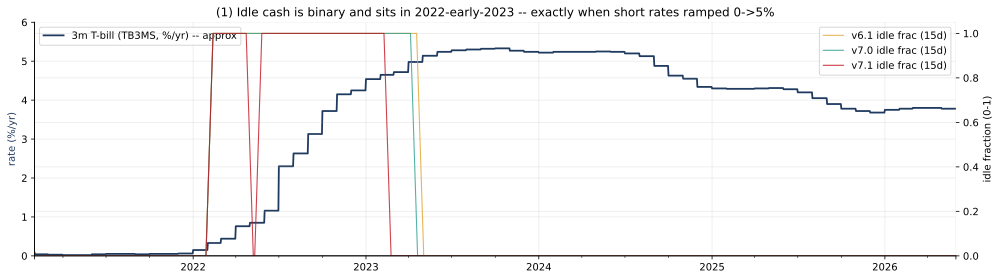

idle>0.5 by year (%):
      v6.1  v7.0  v7.1
2021   0.0   0.0   0.0
2022  92.3  92.3  87.4
2023  29.6  26.0  10.7
2024   0.0   0.0   0.0
2025   0.0   0.0   0.0
2026   0.0   0.0   0.0


In [2]:
fig, ax = plt.subplots(figsize=(14,4))
idx = BOOKS['v7.0']['r'].index
(BOOKS['v7.0']['rf']*YEAR*100).plot(ax=ax, color=NAVY, lw=1.8, label='3m T-bill (TB3MS, %/yr) -- approx')
ax.set_ylabel('rate (%/yr)', color=NAVY); ax.set_ylim(0,6); ax.legend(loc='upper left')
ax2 = ax.twinx(); ax2.grid(False)
for n,c in [('v6.1',AMBER),('v7.0',TEAL),('v7.1',RED)]:
    b = BOOKS[n]; (b['idle'].rolling(15).mean()).plot(ax=ax2, color=c, lw=1.1, alpha=0.8, label=f'{n} idle frac (15d)')
ax2.set_ylabel('idle fraction (0-1)'); ax2.set_ylim(0,1.05); ax2.legend(loc='upper right')
ax.set_title('(1) Idle cash is binary and sits in 2022-early-2023 -- exactly when short rates ramped 0->5%')
plt.tight_layout(); plt.show()
# idle by year
iy = pd.DataFrame({n: (BOOKS[n]['idle']>0.5).groupby(BOOKS[n]['idle'].index.year).mean()*100 for n in RUNS}).round(1)
print('idle>0.5 by year (%):'); print(iy.to_string())

## 2. Before vs after --- the honest table

`net_with_cash = net + idle * rf_daily`. Total return rises for every book. The **maxDD story is
nuanced**: for v6.1 and v7.0 the maximum drawdown occurs in a *deployed* period (2024-25), not in the
idle window, so crediting 2022 cash lifts the flat 2022 segment but leaves the maxDD unchanged ---
Calmar still improves via the numerator. For **v7.1** the maxDD is idle-window-adjacent and *does*
shrink (-1.11% -> -0.88%). **Raw vs excess Sharpe:** raw Sharpe rises everywhere but part of that is
mechanical; the fair number is the excess-of-rf Sharpe. Note the current books' excess Sharpe
(~4.4-4.6 at 1x) sits far below their raw ~7 --- that is the honest cost of a 5% cash benchmark. v8.0
raises the excess Sharpe too, because it removes the idle-day opportunity-cost drag (a flat book earns
0 while cash earns rf, so the uncredited book is *penalized* on idle days in excess-of-rf terms).

In [3]:
def row(book, series, rf):
    p = perf(series, rf)
    return {'ann %': p['ann']*100, 'maxDD %': p['maxdd']*100, 'Calmar': p['calmar'],
            'raw Sharpe': p['sharpe'], 'exc Sharpe': p['exc_sharpe']}
tab = {}
for n, b in BOOKS.items():
    tab[(n,'1x  current')]   = row(b, b['net'],        b['rf'])
    tab[(n,'1x  +cash v8')]  = row(b, b['net']+b['idle']*b['rf'],  b['rf'])
    tab[(n,'2x  current')]   = row(b, b['net2'],       b['rf'])
    tab[(n,'2x  +cash v8')]  = row(b, b['net2']+b['idle']*b['rf'], b['rf'])
T = pd.DataFrame(tab).T.round({'ann %':2,'maxDD %':2,'Calmar':2,'raw Sharpe':2,'exc Sharpe':2})
print(T.to_string())

                   ann %  maxDD %  Calmar  raw Sharpe  exc Sharpe
v6.1 1x  current    9.94    -0.88   11.25        6.78        4.43
     1x  +cash v8  10.57    -0.88   11.97        7.26        4.89
     2x  current    7.69    -1.46    5.27        5.18        2.89
     2x  +cash v8   8.33    -1.46    5.70        5.64        3.33
v7.0 1x  current   10.23    -0.88   11.58        7.00        4.64
     1x  +cash v8  10.83    -0.88   12.25        7.46        5.08
     2x  current    7.98    -1.46    5.46        5.40        3.09
     2x  +cash v8   8.58    -1.46    5.87        5.83        3.51
v7.1 1x  current   10.22    -1.11    9.17        6.97        4.62
     1x  +cash v8  10.68    -0.88   12.08        7.32        4.95
     2x  current    7.77    -2.28    3.40        5.18        2.92
     2x  +cash v8   8.23    -1.84    4.48        5.50        3.23


## 3. The 2022 effect and the equity / drawdown curves

The clearest visual: in 2022 the traded book is flat (overlay out all year), so its equity line is
dead flat. Crediting idle cash turns that flat segment into a gently rising one --- 2022's
contribution flips from about **0% (v6.1/v7.0) / -0.5% (v7.1)** to **+1.4-2.0%**. Everywhere else the
curves are identical (idle ~0). The drawdown panel shows the same thing: the long shallow 2022-23
"underwater-but-flat" stretch lifts; the deeper deployed-period drawdowns are untouched (v6.1/v7.0) or
modestly reduced (v7.1).

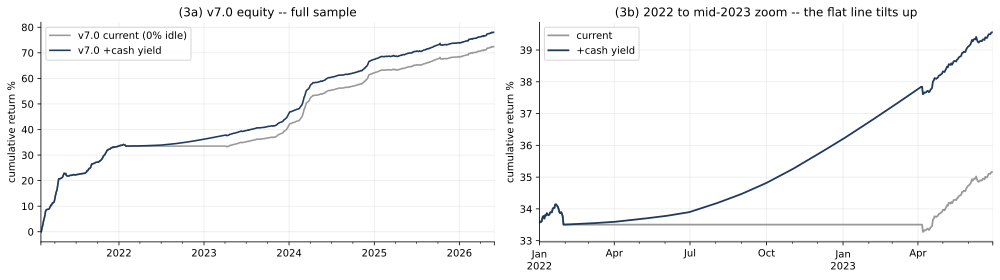

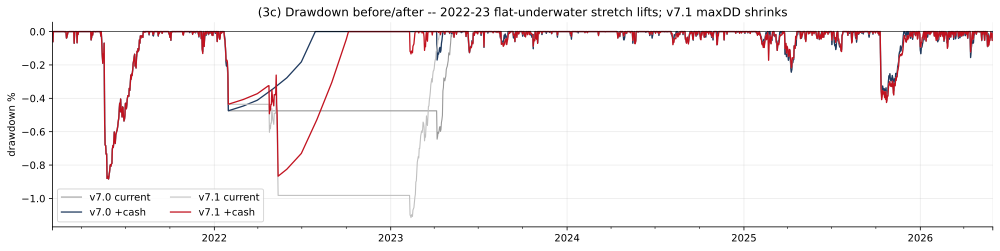

      2022 ret current %  2022 ret +cash %  2022 maxDD cur %  2022 maxDD +cash %
v6.1               -0.02              1.97             -0.47               -0.47
v7.0               -0.02              1.97             -0.47               -0.47
v7.1               -0.53              1.42             -0.98               -0.87


In [4]:
b = BOOKS['v7.0']
eq0 = (1+b['net']).cumprod(); eq1 = (1+b['net']+b['idle']*b['rf']).cumprod()
fig,(a1,a2) = plt.subplots(1,2,figsize=(14,4))
((eq0-1)*100).plot(ax=a1, color=GREY, lw=1.6, label='v7.0 current (0% idle)')
((eq1-1)*100).plot(ax=a1, color=NAVY, lw=1.6, label='v7.0 +cash yield')
a1.set_ylabel('cumulative return %'); a1.legend(); a1.set_title('(3a) v7.0 equity -- full sample')
z = slice('2022-01-01','2023-06-30')
((eq0[z]-1)*100).plot(ax=a2, color=GREY, lw=1.8, label='current')
((eq1[z]-1)*100).plot(ax=a2, color=NAVY, lw=1.8, label='+cash yield')
a2.set_ylabel('cumulative return %'); a2.legend(); a2.set_title('(3b) 2022 to mid-2023 zoom -- the flat line tilts up')
plt.tight_layout(); plt.show()

fig,ax = plt.subplots(figsize=(14,3.6))
for n,c0,c1 in [('v7.0',GREY,NAVY),('v7.1','0.75',RED)]:
    bb = BOOKS[n]
    d0=(lambda e:(e/e.cummax()-1)*100)((1+bb['net']).cumprod())
    d1=(lambda e:(e/e.cummax()-1)*100)((1+bb['net']+bb['idle']*bb['rf']).cumprod())
    d0.plot(ax=ax,color=c0,lw=1.1,label=f'{n} current'); d1.plot(ax=ax,color=c1,lw=1.3,label=f'{n} +cash')
ax.axhline(0,color='k',lw=0.6); ax.set_ylabel('drawdown %'); ax.legend(ncol=2)
ax.set_title('(3c) Drawdown before/after -- 2022-23 flat-underwater stretch lifts; v7.1 maxDD shrinks')
plt.tight_layout(); plt.show()

# 2022 effect, explicit
r2 = {}
for n,b in BOOKS.items():
    n22 = b['net'][b['net'].index.year==2022]; c22 = (b['net']+b['idle']*b['rf'])[b['net'].index.year==2022]
    dd0 = perf(n22)['maxdd']*100; dd1 = perf(c22)['maxdd']*100
    r2[n] = {'2022 ret current %': n22.sum()*100, '2022 ret +cash %': c22.sum()*100,
             '2022 maxDD cur %': dd0, '2022 maxDD +cash %': dd1}
print(pd.DataFrame(r2).T.round(2).to_string())

## 4. Sensitivity to yield capture + achievability

Cash P&L scales linearly with the fraction of the T-bill actually captured. On-venue "Earn" APR is
variable and usually below the T-bill in a high-rate regime; off-venue T-bills capture ~100% but add
transfer operations and settlement latency. Because the idle window is long and persistent (the
overlay re-enters slowly), transfer latency is tolerable, so both routes are viable.

**PM-collateral question (verified via web):** Binance **Simple Earn Flexible USDT** earns a real-time
APR and can back a **Flexible Loan**, but it is **not clearly counted as Portfolio-Margin / uniMMR
collateral** --- PM consolidates the Cross-Margin / USD-M / COIN-M wallets ("Margin-PM"/"Futures-PM"),
and isolated-margin assets are explicitly excluded, so the separate Earn wallet very likely does not
count toward uniMMR. **But this is moot for v8.0:** idle cash exists only when the overlay is **fully
out** --- there are no positions to margin, so there is no collateral competition. A flat book can sit
freely in Simple Earn Flexible (instant, lower/variable APR ~50-75% capture) or be swept to off-venue
T-bills (~100% capture) with no uniMMR impact.

In [5]:
b = BOOKS['v7.0']
sens = {}
for cap in (1.00, 0.75, 0.50):
    s = b['net'] + cap*b['idle']*b['rf']
    p = perf(s, b['rf'])
    sens[f'{int(cap*100)}% capture'] = {'1x ann %': p['ann']*100, 'Calmar': p['calmar'],
                                        'raw Sharpe': p['sharpe'], 'exc Sharpe': p['exc_sharpe']}
sens['0% (current)'] = {'1x ann %': perf(b['net'],b['rf'])['ann']*100, 'Calmar': perf(b['net'])['calmar'],
                        'raw Sharpe': perf(b['net'])['sharpe'], 'exc Sharpe': perf(b['net'],b['rf'])['exc_sharpe']}
print('v7.0 sensitivity to T-bill capture:')
print(pd.DataFrame(sens).T.round(2).to_string())
print()
# mean uplift per book at 100% capture (the 2024-26 rate approx does not matter -- idle=0 there)
up = {n: round((BOOKS[n]['idle']*BOOKS[n]['rf']).mean()*YEAR*100, 3) for n in RUNS}
print('cash-yield mean uplift (%/yr, 100% capture):', up)

v7.0 sensitivity to T-bill capture:
              1x ann %  Calmar  raw Sharpe  exc Sharpe
100% capture     10.83   12.25        7.46        5.08
75% capture      10.68   12.08        7.34        4.97
50% capture      10.53   11.91        7.23        4.86
0% (current)     10.23   11.58        7.00        4.64

cash-yield mean uplift (%/yr, 100% capture): {'v6.1': np.float64(0.633), 'v7.0': np.float64(0.6), 'v7.1': np.float64(0.457)}


## Verdict --- SHIP v8.0 as an accounting correction (config: monthly rate map)

- **Ship it, but frame it honestly.** Crediting idle cash is not alpha --- it is *not* leaving the
  risk-free rate on the table while the overlay parks the whole book in cash through a 5% regime. The
  gain is real but modest: **+0.5-0.6%/yr** on total return, Calmar up for all three books (11.3->12.0
  v6.1, 11.6->12.3 v7.0, **9.2->12.1 v7.1**), and 2022 flips from flat to **+1.4-2.0%**.
- **Do not over-claim maxDD.** For v6.1/v7.0 the maxDD is in a *deployed* window and is **unchanged**;
  only **v7.1**'s maxDD shrinks (-1.11% -> -0.88%). Calmar improves mainly via the return numerator.
- **Quote excess Sharpe alongside raw.** The current books' honest excess-of-rf Sharpe is ~**4.4-4.6**
  (1x) / ~2.9 (2x), well below the ~7 / ~5.2 raw headline --- a 5% cash benchmark is a large haircut on
  a market-neutral book. v8.0 lifts the excess Sharpe (~4.6->5.1 for v7.0 at 1x) because it removes the
  idle-day drag. **The summary should carry `excess_sharpe` next to `sharpe`** regardless of whether
  the cash credit ships.
- **Config shape: a monthly `rf_apr` map, not a flat APR.** The entire effect lives in 2022's 0->5%
  ramp; a single flat APR would misprice exactly the window that matters (early-2022 idle at ~0.3%
  vs late-2022 at ~4%). A 12-24 row `{YYYY-MM: apr}` schedule (engine credits
  `idle_t * apr_month/365`) captures it faithfully and stays trivially auditable. Add a
  `capture` scalar (default ~0.75 on-venue, 1.0 off-venue) for the achievability haircut.
- **Caveats.** Rates here are a labeled approximation (FRED fetch blocked); 2021-23 are reliable and
  2024-26 do not affect the result (idle=0). Single overlay-out episode drives nearly all the benefit,
  so this rides on the v4 overlay continuing to go fully to cash in stress --- the cash credit is a
  by-product of that design, not an independent edge.